# Gyroscope: convert, explore, and test an "accel AND gyro" fall rule (FallAllD, wrist D2)

**The idea:** the accelerometer alone raises far too many alarms (jogging, hopping and hitting a table also make big spikes). A real fall usually also **rotates the wrist fast** while the person goes down. So:

- accel says fall **and** gyro says fall -> **fall**
- accel says fall but gyro says no -> **not a fall**

This is a standard "confirmation" design. The catch: a second condition can only *remove* alarms. It removes false ones (good), but it may also remove real falls that don't rotate much (bad). So we measure both.

**Steps:** 1. find the gyro's real unit, 2. load data in proper units, 3. explore the gyro (EDA), 4. build and test the rule.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve, confusion_matrix

import fad_utils as fu          # shared loading / windowing code (same folder)

pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
TEST_SUBJECTS = [1, 11, 12]     # same held-out people as fallalld_wrist_fall_classifier.ipynb
SEED = 42

## Step 1. What unit is the gyroscope in?

The files store raw numbers ("counts"). We need **deg/s**. The sampling rates (238 Hz accel/gyro, 80 Hz magnetometer) match the ST **LSM9DS1** chip. Its gyro can be set to 8.75, 17.5 or 70 milli-deg/s per count, so which setting did they use?

**Test it with physics.** When the wrist goes from one still pose to another, the accelerometer tells us how far gravity turned (for example 60 degrees). If we add up the gyro readings in between using the *right* scale, we must get the same turn. Wrong scales will be off by 2-8x.

We also check a simple rule of physics: the gyro's total rotation can never be *smaller* than the turn the accelerometer saw.

In [2]:
FS = fu.FS_IN

def still_runs(mask, minlen):
    out, i, n = [], 0, len(mask)
    while i < n:
        if mask[i]:
            j = i
            while j < n and mask[j]: j += 1
            if j - i >= minlen: out.append((i, j))
            i = j
        else:
            i += 1
    return out

def rotate_gravity(g, w_rad):
    # follow the gravity direction through the gyro readings, step by step (Rodrigues rotation)
    for th in w_rad / FS:
        a = np.linalg.norm(th)
        if a > 0:
            k = th / a
            g = g * np.cos(a) + np.cross(k, g) * np.sin(a) + k * np.dot(k, g) * (1 - np.cos(a))
    return g

def angle(u, v):
    return np.degrees(np.arccos(np.clip(np.dot(u, v) / np.linalg.norm(u) / np.linalg.norm(v), -1, 1)))

# collect "still -> turn -> still" moments from raw 238 Hz wrist recordings
pairs = []
files = sorted(fu.FAD_ROOT.glob('S??_D2_A???_T*_A.dat'))
for p in np.random.default_rng(0).permutation(files)[:800]:
    A = fu.read_dat(p) / fu.ACC_COUNTS_PER_G
    G = fu.read_dat(fu.gyro_path(p)).astype(float)
    m = np.linalg.norm(A, axis=1)
    still = (pd.Series(m).rolling(60, center=True).std().to_numpy() < 0.015) & (np.abs(m - 1) < 0.08)
    R = still_runs(still, 60)
    for (a0, a1), (b0, b1) in zip(R, R[1:]):
        g1, g2 = A[a1 - 30:a1].mean(0), A[b0:b0 + 30].mean(0)
        if (b0 - a1) / FS <= 4 and angle(g1, g2) > 30:
            pairs.append((g1, g2, G[a1:b0] - G[a0:a1].mean(0), angle(g1, g2)))
            break
pairs = pairs[:150]
print(f'{len(pairs)} still->turn->still moments | median turn seen by the accelerometer: {np.median([q[3] for q in pairs]):.0f} deg')

rows = []
for scale in (0.00875, 0.0175, 0.070):
    err = [angle(rotate_gravity(g1 / np.linalg.norm(g1), np.radians(w * scale)), g2) for g1, g2, w, _ in pairs]
    path = [np.linalg.norm(w, axis=1).sum() * scale / FS / ang for _, _, w, ang in pairs]
    rows.append({'deg/s per count': scale, 'median error (deg)': np.median(err),
                 'impossible cases (gyro turned less than accel saw)': np.mean(np.array(path) < 1)})
pd.DataFrame(rows).set_index('deg/s per count')

135 still->turn->still moments | median turn seen by the accelerometer: 67 deg


,median error (deg),impossible cases (gyro turned less than accel saw)
deg/s per count,,
0.009,63.999,0.956
0.018,57.505,0.807
0.070,5.410,0.000


**Result:** only **0.070 deg/s per count** (the chip's +/-2000 deg/s setting) makes the gyro agree with the accelerometer, and it is the only one that never breaks physics. That value is now in `fad_utils.GYRO_DPS_PER_COUNT`.

(Side note: this gyro turns "the other way round" compared with the textbook formula, which is just a sign convention. It does not matter here because we use the gyro's *size*, not its direction.)

## Step 2. Load the wrist data in real units

`fad_utils.load_device` converts accel to **g** and gyro to **deg/s**, resamples to **50 Hz** like our sensor, and removes the gyro **bias** (the small reading a still gyro shows when it should read 0). Then we cut the same 2.5 s windows and labels as the first notebook.

In [3]:
trials, ACC, GYR = fu.load_device()
win_meta, X_acc, X_gyr, starts, impact = fu.make_windows(ACC, GYR, trials)
X = fu.make_features(X_acc, X_gyr)
print(f'recordings {len(trials)} | windows {len(win_meta):,} | fall windows {win_meta.y.sum():,}')

calm = X['am_std'] < 0.01                     # windows where the wrist is basically still
print(f'gyro in calm windows (should be ~0 deg/s): median {X.loc[calm, "gm_mean"].median():.1f} deg/s')
print('peak gyro over all daily-activity windows (deg/s):', X.loc[win_meta.y == 0, 'gm_max'].quantile([.5, .9, .99]).round(0).to_dict())

recordings 2515 | windows 37,725 | fall windows 1,045
gyro in calm windows (should be ~0 deg/s): median 1.6 deg/s
peak gyro over all daily-activity windows (deg/s): {0.5: 110.0, 0.9: 349.0, 0.99: 695.0}


## Step 3. Explore the gyro (EDA)

**3a. Do falls rotate the wrist more than normal life?** Below: the biggest rotation speed in each window, for fall windows vs not-fall windows.

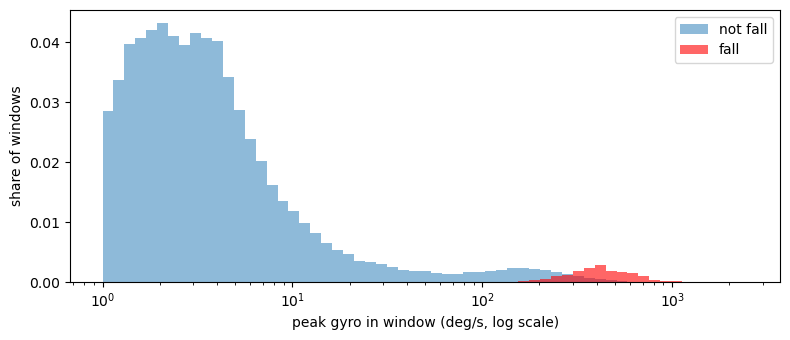

              count    mean     std    min      5%     50%     95%       max
y                                                                           
not fall 36,680.000 145.014 157.323  0.301   1.949 110.371 437.582 1,324.291
fall      1,045.000 507.442 198.194 85.581 249.832 469.177 891.927 1,221.427


In [4]:
bins = np.logspace(0, np.log10(2500), 60)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(X.loc[win_meta.y == 0, 'gm_max'], bins=bins, density=True, alpha=0.5, label='not fall')
ax.hist(X.loc[win_meta.y == 1, 'gm_max'], bins=bins, density=True, alpha=0.6, color='red', label='fall')
ax.set_xscale('log'); ax.set_xlabel('peak gyro in window (deg/s, log scale)'); ax.set_ylabel('share of windows'); ax.legend()
plt.tight_layout(); plt.show()
print(X.groupby(win_meta.y)['gm_max'].describe(percentiles=[.05, .5, .95]).rename(index={0: 'not fall', 1: 'fall'}))

**3b. Accel and gyro together.** Each dot is a window. If the AND idea works, falls (red) should sit in the **top-right**: big spike *and* fast rotation. The dashed line is the 2.5 g accel rule; everything to its right is "accel says fall".

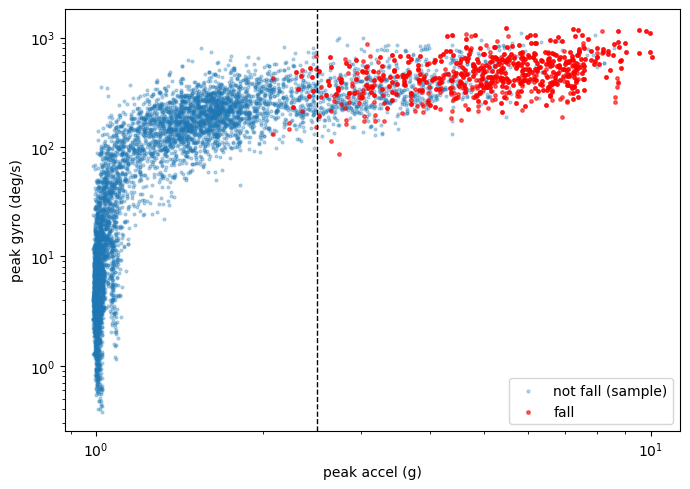

In [5]:
neg = win_meta.index[win_meta.y == 0]
neg = np.random.default_rng(0).choice(neg, 6000, replace=False)
pos = win_meta.index[win_meta.y == 1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X.loc[neg, 'am_max'], X.loc[neg, 'gm_max'], s=4, alpha=0.3, label='not fall (sample)')
ax.scatter(X.loc[pos, 'am_max'], X.loc[pos, 'gm_max'], s=6, alpha=0.6, color='red', label='fall')
ax.axvline(2.5, ls='--', color='k', lw=1)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('peak accel (g)'); ax.set_ylabel('peak gyro (deg/s)'); ax.legend()
plt.tight_layout(); plt.show()

**3c. When does the wrist rotate, compared with the impact?** We look 2 s either side of each fall's impact and find the fastest rotation. Negative = before the impact (during the fall itself).

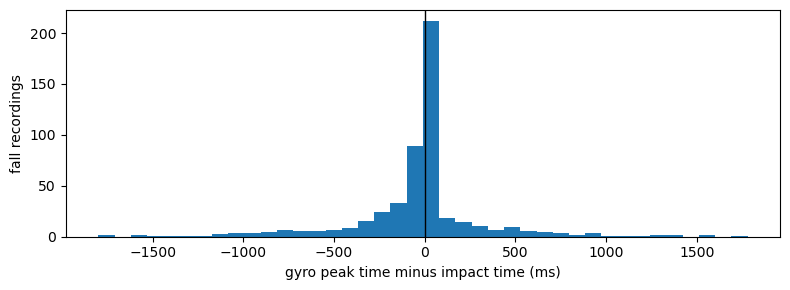

gyro peak relative to impact (ms): {0.1: -436.0, 0.25: -90.0, 0.5: 0.0, 0.75: 40.0, 0.9: 320.0}


In [6]:
GM = np.linalg.norm(GYR, axis=2)                         # (recordings, samples) gyro size
fall_recs = np.where(trials.is_fall)[0]
lag = []
for r in fall_recs:
    lo, hi = max(impact[r] - 2 * fu.FS_OUT, 0), min(impact[r] + 2 * fu.FS_OUT, GM.shape[1])
    lag.append((lo + GM[r, lo:hi].argmax() - impact[r]) / fu.FS_OUT * 1000)
lag = pd.Series(lag)
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(lag, bins=40); ax.axvline(0, color='k', lw=1); ax.set_xlabel('gyro peak time minus impact time (ms)'); ax.set_ylabel('fall recordings')
plt.tight_layout(); plt.show()
print('gyro peak relative to impact (ms):', lag.quantile([.1, .25, .5, .75, .9]).round(0).to_dict())

**3d. The cases that decide whether the rule works.**
- *Left table:* daily activities that **pass the accel test** (> 2.5 g). These are today's false alarms. How fast do they rotate? If slowly, the gyro check removes them.
- *Right table:* **fall types that rotate the least.** These are the falls the gyro check could wrongly throw away.

"Gyro near impact" = the fastest rotation within 1 s either side of the window's accel peak.

In [7]:
def gyro_near_peak(T_s):
    # fastest rotation within +/- T_s seconds of each window's biggest accel spike (looks outside the window if needed)
    T = int(T_s * fu.FS_OUT)
    k = win_meta.start.to_numpy() + np.linalg.norm(X_acc, axis=2).argmax(axis=1)
    rec = win_meta.rec.to_numpy()
    out = np.empty(len(k), dtype='float32')
    for i, (r, c) in enumerate(zip(rec, k)):
        out[i] = GM[r, max(c - T, 0):c + T + 1].max()
    return out

X['g_near_1s'] = gyro_near_peak(1.0)
adl_hits = win_meta[(win_meta.y == 0) & (X.am_max > 2.5)].assign(g=X.g_near_1s)
left = adl_hits.groupby('activity').g.agg(windows='size', median_gyro='median').sort_values('windows', ascending=False).head(10)
falls = win_meta[win_meta.y == 1].assign(g=X.g_near_1s)
right = falls.groupby('activity').g.agg(windows='size', median_gyro='median', lowest_gyro='min').sort_values('median_gyro').head(10)
print(f'Not-fall windows that pass the 2.5 g accel test: {len(adl_hits):,} (activity code = FallAllD ADL code)')
display(left)
print('Fall types with the least rotation (deg/s):')
display(right)

Not-fall windows that pass the 2.5 g accel test: 4,350 (activity code = FallAllD ADL code)


,windows,median_gyro
activity,,
24,453,344.072
25,435,459.970
3,253,292.810
44,243,346.266
2,239,291.307
43,235,340.203
1,224,288.284
36,166,207.711
27,132,523.679


Fall types with the least rotation (deg/s):


,windows,median_gyro,lowest_gyro
activity,,,
135,22,257.098,145.121
115,16,372.504,301.808
104,28,401.552,271.182
106,24,409.600,264.849
116,18,412.859,237.010
127,62,420.077,131.589
124,36,423.577,265.169
122,30,428.268,315.233
128,50,438.644,240.858


## Step 4. Build and test the AND rule

`fall = (peak accel > A) AND (gyro near the peak > G)`

We try many combinations of **A** (accel threshold), **G** (gyro threshold, where 0 means no gyro check, i.e. the accel-only rule) and **T** (how far around the impact to look for rotation). We choose the one with the **fewest false alarms that still catches >= 95% of fall windows**, using the **training people only**. Then we test once on the 3 held-out people.

In [8]:
for T in (0.5, 1.0, 1.5):
    X[f'g_near_{T}s'] = gyro_near_peak(T)

is_test = win_meta.subject.isin(TEST_SUBJECTS).to_numpy()
assert set(win_meta.subject[is_test]).isdisjoint(set(win_meta.subject[~is_test]))
y = win_meta.y.to_numpy(); ytr, yte = y[~is_test], y[is_test]

grid = []
for T in (0.5, 1.0, 1.5):
    g = X[f'g_near_{T}s'].to_numpy()
    for A in (2.0, 2.5, 3.0, 3.5, 4.0):
        for G in range(0, 801, 50):
            pred = (X.am_max.to_numpy() > A) & (g > G)
            tp = (pred & (y == 1))[~is_test].sum(); fp = (pred & (y == 0))[~is_test].sum()
            grid.append({'T_s': T, 'A_g': A, 'G_dps': G, 'recall': tp / ytr.sum(), 'FP': fp})
grid = pd.DataFrame(grid)
ok = grid[grid.recall >= 0.95].sort_values(['FP', 'recall'], ascending=[True, False])
best_rule = ok.iloc[0]
best_accel_only = grid[(grid.G_dps == 0) & (grid.recall >= 0.95)].sort_values('FP').iloc[0]
print('Best AND rule on TRAIN people:'); display(best_rule.to_frame().T)
print('Best accel-only rule on TRAIN people (same recall target):'); display(best_accel_only.to_frame().T)

Best AND rule on TRAIN people:


,T_s,A_g,G_dps,recall,FP
21,0.500,2.500,200.000,0.952,"3,094.000"


Best accel-only rule on TRAIN people (same recall target):


,T_s,A_g,G_dps,recall,FP
17,0.500,2.500,0.000,0.972,"3,470.000"


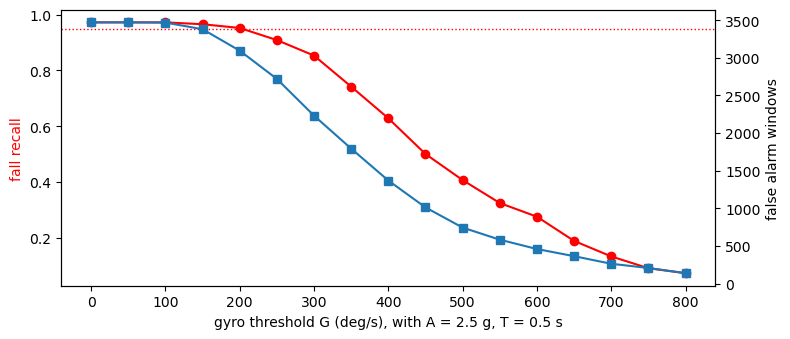

In [9]:
# How do false alarms and recall change as the gyro threshold rises? (train people, best A and T)
sub = grid[(grid.A_g == best_rule.A_g) & (grid.T_s == best_rule.T_s)]
fig, ax1 = plt.subplots(figsize=(8, 3.5))
ax1.plot(sub.G_dps, sub.recall, marker='o', color='red'); ax1.set_ylabel('fall recall', color='red'); ax1.axhline(0.95, color='red', ls=':', lw=1)
ax2 = ax1.twinx(); ax2.plot(sub.G_dps, sub.FP, marker='s'); ax2.set_ylabel('false alarm windows')
ax1.set_xlabel(f'gyro threshold G (deg/s), with A = {best_rule.A_g} g, T = {best_rule.T_s} s'); plt.tight_layout(); plt.show()

In [10]:
# Random forest for comparison (same recipe as the first notebook, gyro now in deg/s)
feat_cols = [c for c in X.columns if not c.startswith('g_near')]
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)
cv_p = cross_val_predict(rf, X.loc[~is_test, feat_cols], ytr, groups=win_meta.subject[~is_test], cv=GroupKFold(5), method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(ytr, cv_p)
rf_thr = float(thr[rec[:-1] >= 0.90][-1])
rf.fit(X.loc[~is_test, feat_cols], ytr)

test_meta = win_meta[is_test].reset_index(drop=True)
neg_hours = (yte == 0).sum() * fu.HOP / fu.FS_OUT / 3600

def evaluate(name, pred):
    pred = np.asarray(pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
    caught = test_meta.assign(pred=pred)[yte == 1].groupby('rec').pred.max()
    return {'model': name, 'recall': tp / (tp + fn), 'precision': tp / max(tp + fp, 1), 'false alarms / hour': fp / neg_hours,
            'fall recordings caught': f'{int(caught.sum())}/{len(caught)}', 'TP': tp, 'FN': fn, 'FP': fp}

Xt = X[is_test]
rows = [
    evaluate('accel only: peak > 2.5 g', Xt.am_max > 2.5),
    evaluate(f'accel only (tuned): peak > {best_accel_only.A_g} g', Xt.am_max > best_accel_only.A_g),
    evaluate(f'AND rule: > {best_rule.A_g} g and gyro > {int(best_rule.G_dps)} deg/s (+/-{best_rule.T_s} s)',
             (Xt.am_max > best_rule.A_g) & (Xt[f'g_near_{best_rule.T_s}s'] > best_rule.G_dps)),
    evaluate('random forest', rf.predict_proba(Xt[feat_cols])[:, 1] >= rf_thr),
]
results = pd.DataFrame(rows).set_index('model')
print(f'TEST people {TEST_SUBJECTS}: {len(yte):,} windows, {int(yte.sum())} fall windows, {neg_hours:.2f} h of not-fall data')
results

TEST people [1, 11, 12]: 8,310 windows, 146 fall windows, 2.81 h of not-fall data


,recall,precision,false alarms / hour,fall recordings caught,TP,FN,FP
model,,,,,,,
accel only: peak > 2.5 g,1.000,0.142,312.940,73/73,146,0,880
accel only (tuned): peak > 2.5 g,1.000,0.142,312.940,73/73,146,0,880
AND rule: > 2.5 g and gyro > 200 deg/s (+/-0.5 s),1.000,0.159,274.533,73/73,146,0,772
random forest,0.979,0.627,30.227,73/73,143,3,85


In [11]:
# Which falls did the AND rule miss on the test people? (per recording)
and_pred = ((Xt.am_max > best_rule.A_g) & (Xt[f'g_near_{best_rule.T_s}s'] > best_rule.G_dps)).astype(int).to_numpy()
per = test_meta.assign(pred=and_pred)[yte == 1].groupby('rec').agg(activity=('activity', 'first'), caught=('pred', 'max'))
missed = per[per.caught == 0]
print(f'missed fall recordings: {len(missed)} of {len(per)}', '| fall types:', sorted(missed.activity.unique().tolist()))

missed fall recordings: 0 of 73 | fall types: []


## What we learned

**1. The gyro unit is now known:** 0.070 deg/s per count (+/-2000 deg/s). Only this scale agrees with the accelerometer (5 deg median error vs 58-64 deg for the others). A still wrist reads ~1.6 deg/s after bias removal, which is close to 0 as expected.

**2. Falls do rotate the wrist hard.** Typical fall window: ~470 deg/s peak; even the slowest 5% of falls reach ~250 deg/s. Typical daily window: ~110 deg/s.

**3. ...but so does everything else that fools the accelerometer.** The daily activities that already pass the 2.5 g test (today's false alarms) *also* rotate fast: their medians are ~200-520 deg/s, overlapping the falls. Hitting, swinging and hopping are fast wrist rotations too.

**4. So the AND rule only helps a little** (3 unseen people):

| | recall | false alarms / hour |
|---|---|---|
| accel only (> 2.5 g) | 100% | ~313 |
| **accel AND gyro (> 2.5 g and > 200 deg/s within 0.5 s)** | **100%** | **~275** (about 12% fewer) |
| random forest | 98% | ~30 |

It lost no falls, which is good: your concern about missing falls did not happen here. But it removed only about 1 in 8 false alarms, because a higher gyro threshold starts dropping real falls (see the threshold plot).

**5. Timing surprise:** the fastest rotation happens almost exactly *at* the impact (median 0 ms, middle half between -90 and +40 ms), not well before it. The wrist slams and spins at the moment of impact.

**Bottom line:** "accel AND gyro" is a reasonable, explainable idea and safe for recall, but on this data a single gyro threshold is a weak filter. The random forest is ~9x better because it combines many signals at once (how sudden, how big, the range on each axis, rotation...). The biggest win from the gyro is as one of many inputs, not as a yes/no gate.

**Ideas that are more likely to cut false alarms:**
- Add the third check from `context.md`: **stillness after the impact** (a fallen person lies still; a jogger keeps moving). This needs a longer window after the spike.
- Use orientation change: did the wrist end up in a different pose for several seconds after the event?
- Note that some "false alarms" are windows *next to* a real fall's impact (for example code 124 in the table). They are labelled not-fall but contain fall motion. Counting alarms per event, not per window, would make the numbers fairer.

**Limits:** same as before. There are only 3 test people, the volunteers are young and fell onto a mattress, D2 = wrist is not officially confirmed, and the daily activities are short and staged.